# Day 7 · Advanced Training Techniques
Add `nn.BatchNorm1d` and `nn.Dropout(0.3)` to the Day 6 model, train 50 epochs, compare curves against the plain baseline.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("crop_yield.csv")          # put crop_yield.csv next to this notebook
print(df.shape)
df.head()

(1000000, 10)


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251


In [2]:
import torch, torch.nn as nn
from sklearn.preprocessing import StandardScaler
device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("device:", device)
torch.manual_seed(42)

sub = df.sample(100_000, random_state=42).reset_index(drop=True)      # subsample keeps CPU training quick
classes = sorted(sub["Soil_Type"].unique()); print("soil classes:", classes)
y = sub["Soil_Type"].map({c: i for i, c in enumerate(classes)}).to_numpy()
X = pd.get_dummies(sub.drop(columns=["Soil_Type"]), columns=["Region", "Crop", "Weather_Condition"]).astype(float).to_numpy()
cut = int(0.8 * len(sub))
sc = StandardScaler().fit(X[:cut])
Xtr = torch.tensor(sc.transform(X[:cut]), dtype=torch.float32).to(device); ytr = torch.tensor(y[:cut]).to(device)
Xte = torch.tensor(sc.transform(X[cut:]), dtype=torch.float32).to(device); yte = torch.tensor(y[cut:]).to(device)
print("chance accuracy ~", round(1 / len(classes), 3))

def train(model, epochs, bs=512, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr); lossf = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "train_acc": [], "test_acc": []}
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr), device=device); tot = 0.0
        for i in range(0, len(Xtr), bs):
            b = perm[i:i+bs]; opt.zero_grad(); loss = lossf(model(Xtr[b]), ytr[b]); loss.backward(); opt.step(); tot += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            tr_acc = (model(Xtr).argmax(1) == ytr).float().mean().item(); te_acc = (model(Xte).argmax(1) == yte).float().mean().item()
        hist["train_loss"].append(tot / len(Xtr)); hist["train_acc"].append(tr_acc); hist["test_acc"].append(te_acc)
        if ep % 5 == 0 or ep == epochs - 1: print(f"epoch {ep:2d}  loss {hist['train_loss'][-1]:.4f}  train acc {tr_acc:.3f}  test acc {te_acc:.3f}")
    return hist

device: cpu
soil classes: ['Chalky', 'Clay', 'Loam', 'Peaty', 'Sandy', 'Silt']
chance accuracy ~ 0.167


In [3]:
def make(reg):
    layers = [nn.Linear(Xtr.shape[1], 64)]
    if reg: layers += [nn.BatchNorm1d(64)]
    layers += [nn.ReLU()]
    if reg: layers += [nn.Dropout(0.3)]
    layers += [nn.Linear(64, 32)]
    if reg: layers += [nn.BatchNorm1d(32)]
    layers += [nn.ReLU()]
    if reg: layers += [nn.Dropout(0.3)]
    layers += [nn.Linear(32, len(classes))]
    return nn.Sequential(*layers).to(device)

print("--- baseline (Day 6)"); torch.manual_seed(42); h_base = train(make(False), epochs=50)
print("--- BatchNorm + Dropout(0.3)"); torch.manual_seed(42); h_reg = train(make(True), epochs=50)

--- baseline (Day 6)


epoch  0  loss 1.7934  train acc 0.174  test acc 0.169


epoch  5  loss 1.7900  train acc 0.185  test acc 0.169


epoch 10  loss 1.7882  train acc 0.193  test acc 0.165


epoch 15  loss 1.7862  train acc 0.200  test acc 0.167


epoch 20  loss 1.7839  train acc 0.201  test acc 0.168


... (13 outputs left out)

epoch 35  loss 1.7901  train acc 0.189  test acc 0.170


epoch 40  loss 1.7895  train acc 0.191  test acc 0.167


epoch 45  loss 1.7893  train acc 0.192  test acc 0.168


epoch 49  loss 1.7894  train acc 0.194  test acc 0.168


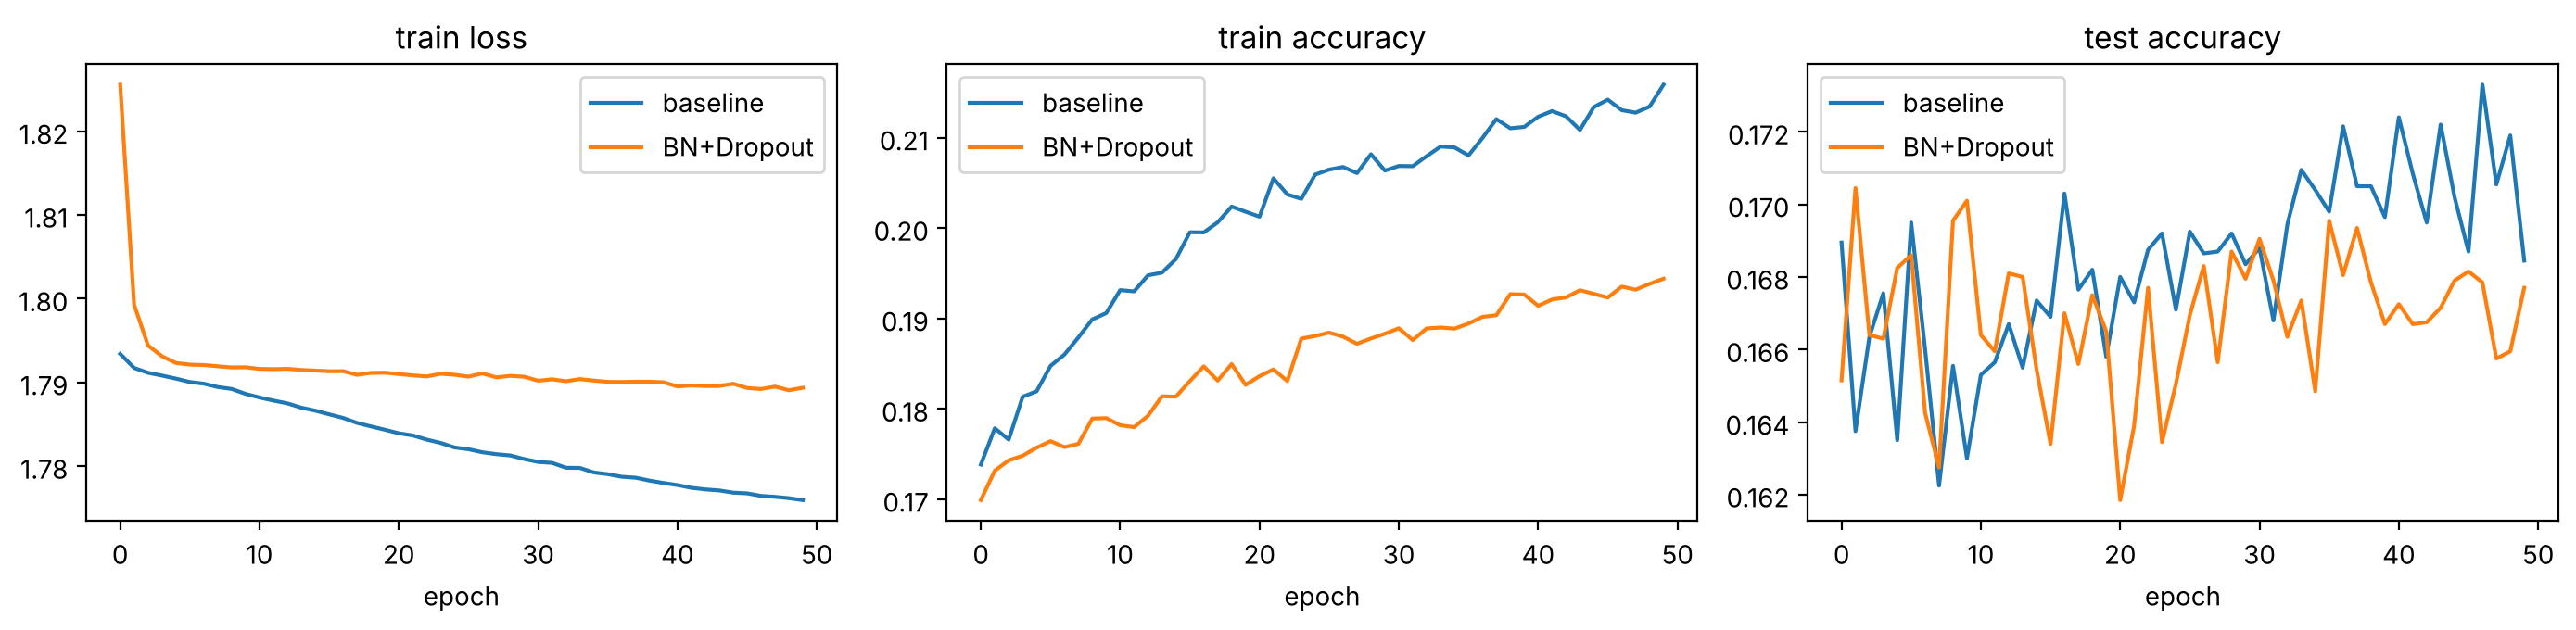

final train-test gap  baseline: +0.047   BN+Dropout: +0.027


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for h, n in ((h_base, "baseline"), (h_reg, "BN+Dropout")):
    ax[0].plot(h["train_loss"], label=n); ax[1].plot(h["train_acc"], label=n); ax[2].plot(h["test_acc"], label=n)
for a, t in zip(ax, ["train loss", "train accuracy", "test accuracy"]): a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()
print(f"final train-test gap  baseline: {h_base['train_acc'][-1]-h_base['test_acc'][-1]:+.3f}   BN+Dropout: {h_reg['train_acc'][-1]-h_reg['test_acc'][-1]:+.3f}")

**Reading the result:** test accuracy stays near chance (1/6 ≈ 0.167). That is a property of this dataset, not a bug: soil type is statistically independent of the other columns, so there is no signal to learn. The train-vs-test gap is the thing to watch here (the model memorises noise), and that is what the Day 7 regularisation comparison shows.